### In-vitro data

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import spikeinterface.full as si

%matplotlib widget

In [23]:
#base_data_folder = Path("/home/samuel/DataSpikeSorting/data_cns_lyon_2025/")
#working_folder = Path("/home/samuel/DataSpikeSorting/data_cns_lyon_2025/results")

# Modify this to where you downloaded your datasets
home = Path.home()
base_data_folder = Path(home / "school_2026/data/")
results_folder = Path(home / "school_2026/results/")

recording_stem = "human_ngn2_100K_c_55D"
recording_name = f"{recording_stem}.brw"
results_folder = results_folder / recording_stem

In [6]:
recording = si.read_biocam(base_data_folder / recording_name)

In [11]:
recording = recording.remove_channels(recording.channel_ids[:1])
recording

ChannelSliceRecording: 4094 channels - 10103.075195 Hz - 1 segments - 1,211,049 samples 
                       119.87s (2.00 minutes) - int16 dtype - 9.24 GiB

In [13]:
recording_processed = si.bandpass_filter(recording, freq_max=5000, dtype='float32')
recording_processed = si.common_reference(recording_processed)

In [14]:
recording_processed

CommonReferenceRecording: 4094 channels - 10103.075195 Hz - 1 segments - 1,211,049 samples 
                          119.87s (2.00 minutes) - float32 dtype - 18.47 GiB

In [15]:
from spikeinterface.sortingcomponents.peak_detection import detect_peaks
from spikeinterface.sortingcomponents.peak_localization import localize_peaks

In [16]:
si.set_global_job_kwargs(n_jobs=-1, chunk_duration="100ms")

In [17]:
peaks = detect_peaks(
    recording_processed,
    method="locally_exclusive",
    method_kwargs=dict(
        detect_threshold=6.,
        exclude_sweep_ms=0.1,
        radius_um=75.)
)

noise_level (workers: 20 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

detect peaks (locally_exclusive) (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?it/s]

In [18]:
import matplotlib.pyplot as plt

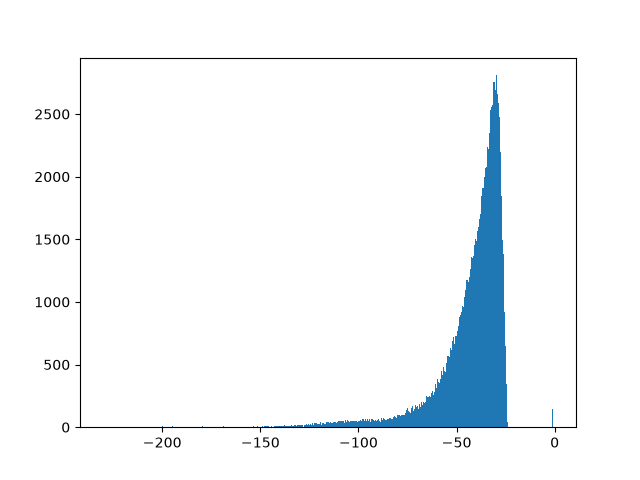

In [19]:
fig, ax = plt.subplots()
a = ax.hist(peaks['amplitude'], bins=500)

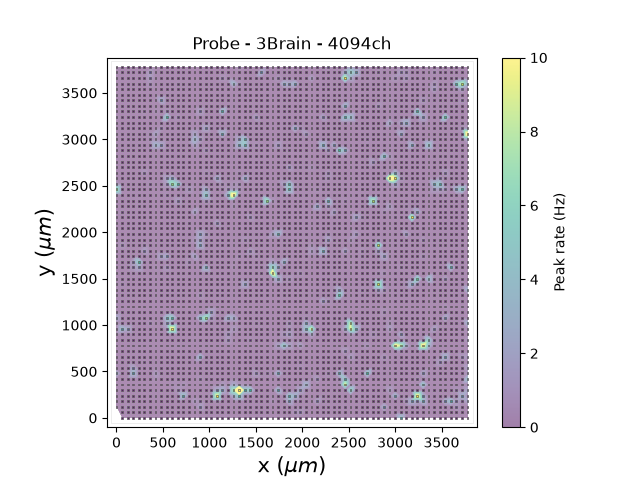

In [20]:
si.plot_peak_activity(recording, peaks, color_range=[0, 10])

In [21]:
sorting =si.NumpySorting.from_peaks(peaks, recording.sampling_frequency, recording.channel_ids)
sorting

NumpySorting: 4094 units - 1 segments - 10.1kHz

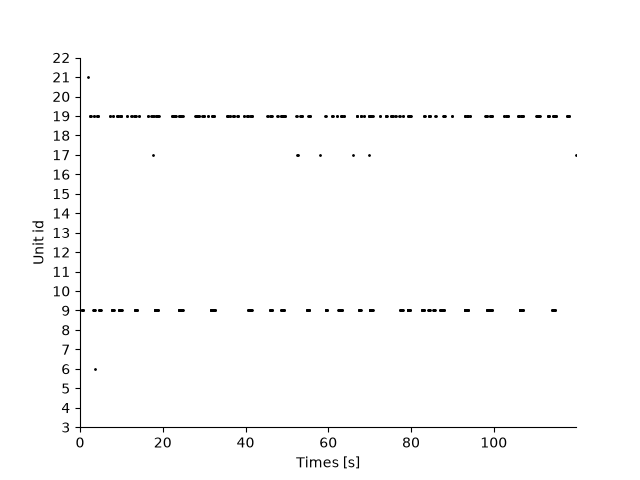

In [22]:
si.plot_rasters(sorting, unit_ids=sorting.unit_ids[:20])

In [24]:
sorting_lupin = si.run_sorter(sorter_name="lupin", recording=recording_processed, 
                           folder= results_folder / "sorter_lupin",
                           verbose=True, remove_existing_folder=True, apply_preprocessing=False, apply_motion_correction=False)


                            .::----::..
                 ..:-+#%*+#%@@@@@@@+..:+#+.
                .+@%%@@@@@@@@@@@@@@#:  .=@=
                -@@@@@@@@@@@@@@@@@@%-. .=@*
                .@@@@@@@@@@@@@@@@@@@*. .-%#
                 %@@@@@@@@@@@@@@@@@@*.  :#%
                 =%%@@@@@@@@@@@@@@%%+:  .+@.
                 -%#@@@@@@@@@@@@@@%*==  .-@.
                 :#%@@@@@@@@@@@@@@%#+#  .=@.
                 .+%@@@@@@@@@@@@@@@%#@. .+@.
                 .+*#@@@@@@@@@@@@@@@%@. .+@:
                 .=%+@@@@@@@@@@@@@@@@*.  =%-.
                  :#%##@@@@@@@@@@@@%%-.  :%+.
               ..:=**%@@@@@@@@@@@@@@@:.  .%%......
             .+#@%%%@**@%@@@@@@@@@@@*....=%@%@@@@@%=..
            .*@@@@@@@@@@@=#@@@@@@@@@@*=:.:.#@@@@@@%%-.
           .-%%@@@@@@@@@@@@@#+%@+-::-+=:=::+@@@@@@##-.
           .:%@@@@@@@@@@@@@@@@@%+%##*%%%**%@@@@@@##+.
            .+@@@@@@@@@@@@@@@@#***++***@@@@@@@@%%%=.
             .:*@@@@@@@@%=-.....   ....:-*%%%%%+-.
                 ..:-:..
                       

noise_level (workers: 20 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

get protoype waveforms (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?it/s]

detect peaks (matched_filtering) (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?it/s]

detect_peaks(): 275998 peaks found
select_peaks(): 275998 peaks kept for clustering


Fit peaks svd (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?it/s]

... (3 outputs left out)

estimate_templates_with_accumulator (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?it/s]

find spikes (wobble) (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?it/s]

/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/curation/auto_merge.py:502: UserWarning: Units (np.int64(3414), np.int64(4445)) can not be merged with the current sparsity_overlap. Merging is skipped
  warnings.warn(
/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/curation/auto_merge.py:502: UserWarning: Units (np.int64(4218), np.int64(4547)) can not be merged with the current sparsity_overlap. Merging is skipped
  warnings.warn(
/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/curation/auto_merge.py:502: UserWarning: Units (np.int64(4409), np.int64(4429), np.int64(4591)) can not be merged with the current sparsity_overlap. Merging is skipped
  warnings.warn(
/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/core_tools.py:988: UserWarning: The extractor is not serializable to file. The p

lupin run time 667.82s


In [26]:
analyzer = si.create_sorting_analyzer(sorting_lupin, recording_processed)
analyzer.compute({
    "random_spikes" : {},
    "templates": {},
    "waveforms": {},
    "noise_levels": {},
    "correlograms": {},
    "noise_levels": {},
    "spike_amplitudes": {},
    "spike_locations": {},
    "template_metrics": {},
    "unit_locations": {},
    "template_similarity": {},
    "quality_metrics": {},
})

compute_waveforms (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?it/s]

noise_level (workers: 20 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/metrics/template/template_metrics.py:301: UserWarning: With less than 10 channels, multi-channel metrics might not be reliable.
  warnings.warn(


Compute : spike_amplitudes + spike_locations (workers: 20 processes fork):   0%|          | 0/1200 [00:00<?, ?…

/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/analyzer_extension_core.py:1204: UserWarning: The following metrics will not be computed due to missing dependencies: ['silhouette', 'mahalanobis', 'd_prime', 'nearest_neighbor']
  warnings.warn(
/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/py

In [27]:
from spikeinterface_gui import run_mainwindow
run_mainwindow(
    analyzer,
    with_traces=False,
    mode="desktop"
)

/home/pierre/github/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/colorspacious/comparison.py:11: SyntaxWarning: invalid escape sequence '\D'
  """Computes the :math:`\Delta E` distance between pairs of colors.
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x76831aa0 but 0x0 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x76831aa0 but 0x0 is focused
qt.qpa.wayland.textinput: virtual void QtWaylandClient::QWaylandTextInputv3::disableSurface(wl_surface*) Trying to disable 0x76831aa0 but 0x0 is focused


<spikeinterface_gui.backend_qt.QtMainWindow(0x65c50100) at 0x7a63f2330f40>